# 02 · Limpeza, normalização e qualidade de dados

**Coffee Big Data Intelligence**

## Objetivos
1. Entender a passagem **bronze → silver**: parsing, tipagem, normalização de códigos IBGE, chaves temporais.
2. Ver os **testes de qualidade** do pipeline e o que eles encontraram nos dados reais.
3. Entender a **ingestão incremental e idempotente**.
4. Reconciliar **fontes diferentes** (PAM × CONAB) — e aceitar que divergem.
5. Aprender com um **erro real** que o pipeline cometeu e os testes revelaram.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from coffeebdi import config, silver, modeling as M, quality
from coffeebdi.lake import Lake
from coffeebdi.nbutils import duck, mpl_style

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:,.2f}".format)
mpl_style()
lake = Lake()
con = duck(lake)
def q(sql):
    """Executa SQL (DuckDB) sobre as tabelas silver/gold e devolve DataFrame."""
    return con.execute(sql).df()
FIG = config.OUTPUTS / "figures"

## 1. Arquitetura em camadas

```
 APIs/arquivos ──► BRONZE (imutável, bruto, .json.gz + manifesto com sha256)
                      │  parsing, tipagem, normalização de códigos, flags de qualidade
                      ▼
                   SILVER (Parquet particionado, esquema estável, uma linha = um fato)
                      │  agregações, janelas fenológicas, lags, junções, preços reais
                      ▼
                    GOLD (marts para análise e modelagem)  ──► testes de qualidade (dq_results)
```
Diagrama Mermaid completo: `docs/pt-BR/01_arquitetura.md`.

## 2. Normalização de códigos IBGE

O código do município tem 7 dígitos (2 de UF + 4 + **dígito verificador**). Fontes antigas trazem 6 dígitos; planilhas trazem `3538808.0`. O pipeline normaliza e **valida o DV**; códigos inválidos vão para quarentena (`silver/_rejects_*`) em vez de contaminar as análises.

DV: pesos 1,2,1,2,1,2 sobre os 6 primeiros dígitos; produtos ≥ 10 têm os dígitos somados; DV = (10 − soma mod 10) mod 10.

In [2]:
from coffeebdi.ibge import check_digit, normalize_municipio, is_valid_municipio
exemplos = ["3538808", "353880", 3538808.0, "3538807", "3539301"]
rows = []
for e in exemplos:
    try:
        rows.append((e, normalize_municipio(e), is_valid_municipio(normalize_municipio(e)), ""))
    except ValueError as err:
        rows.append((e, None, False, str(err)))
pd.DataFrame(rows, columns=["entrada", "normalizado", "válido", "erro"])

,entrada,normalizado,válido,erro
0,3538808,3538808,True,
1,353880,3538808,True,
2,"3,538,808.00",3538808,True,
3,3538807,NaN,False,DV inválido em 3538807
4,3539301,3539301,True,


Note `3539301`: é um código **válido** — de **Pirassununga**, não de Piraju (3538808). O DV só detecta digitação errada, **não** confusões entre municípios; por isso nomes e códigos são sempre conferidos contra a API de Localidades.

In [3]:
dim = q("select cod_ibge, municipio, uf, microrregiao from dim_municipio")
print("Todos os municípios da dimensão têm DV válido:", dim["cod_ibge"].map(is_valid_municipio).all(), f"({len(dim)} municípios)")
print("Registros em quarentena (código inválido):", q("select count(*) from pam_municipio where cod_ibge is null").iloc[0, 0])

Todos os municípios da dimensão têm DV válido: True (645 municípios)
Registros em quarentena (código inválido): 0


## 3. Valores especiais, qualidade por variável e chaves temporais

Cada variável PAM ganha uma coluna `<variavel>_q` com a qualidade (`ok`, `zero`, `zero_arredondado`, `indisponivel`, `suprimido`, `nao_se_aplica`). **Chaves temporais:** `ano` (inteiro, chave de junção com clima/preço) e `date_key` (1º de janeiro, para séries). Clima diário usa `date` + `ano` + `mes`.

In [4]:
qual = q('''
SELECT especie, quantidade_t_q AS qualidade, count(*) AS linhas FROM pam_municipio GROUP BY 1, 2 ORDER BY 1, 2''')
qual.pivot(index="especie", columns="qualidade", values="linhas").fillna(0).astype(int)

qualidade,indisponivel,ok,zero,zero_arredondado
especie,,,,
arabica,990,4398,3544,0
canephora,990,80,7862,0
total,3767,21183,8225,1


**Interpretação:** a grande maioria das linhas é `zero` (município **sem** café naquele ano — `'-'` no SIDRA) ou `ok`. Linhas `indisponivel` merecem atenção (município existente sem dado). Municípios criados após 1974 simplesmente **não existem** nos anos anteriores.

## 4. Um erro real: `pivot_table` descartava linhas silenciosamente

Na primeira versão da silver, o pivot usava `pivot_table` (que remove linhas cujos valores são todos NaN). Municípios com `'...'` em todas as variáveis **sumiam**. Foi o **teste de completude de anos** que revelou. Reproduzimos a diferença abaixo.

In [5]:
frames = []
for key in lake.keys("ibge_pam", "pam_municipio"):
    _, esp, _ = key.split("_")
    long = silver.flatten_sidra(lake.read_json("ibge_pam", "pam_municipio", key)); long["especie"] = esp
    frames.append(long)
long = pd.concat(frames, ignore_index=True)
vals = long["raw"].map(silver.sidra_value)
long["valor"] = [v for v, _ in vals]; long["var"] = long["var_id"].map(config.PAM_VARS)
idx = ["cod_local", "nome_local", "ano", "especie"]
errado = long.pivot_table(index=idx, columns="var", values="valor", aggfunc="first")   # versão antiga
certo = long.pivot(index=idx, columns="var", values="valor")                           # versão atual
print(f"pivot_table: {len(errado):,} linhas | pivot: {len(certo):,} linhas | perdidas silenciosamente: {len(certo)-len(errado):,}")

pivot_table: 45,293 linhas | pivot: 51,040 linhas | perdidas silenciosamente: 5,747


**Lição:** *testes de qualidade encontram bugs de pipeline, não só problemas de dados.* A checagem `anos_completos` (cada município deve ter todos os anos do intervalo) transformou uma perda silenciosa em falha visível. Teste de regressão: `tests/test_silver.py::test_pivot_keeps_all_nan_rows`.

## 5. Relatório de qualidade (DQ)

O pipeline roda as checagens e grava `gold/dq_results`. Severidade `error` reprova a execução; `warn` registra um achado.

In [6]:
dq = q("select * from dq_results order by severity, passed, \"table\", \"check\"")
dq["falhas"] = dq["n_failed"].astype(str) + " / " + dq["n_total"].astype(str)
print("Resumo:", quality.summarize([quality.CheckResult(**r) for r in dq.drop(columns="falhas").to_dict("records")]))
dq[["table", "check", "severity", "passed", "falhas", "detail"]]

Resumo: {'n_checks': 25, 'n_failed_error': 0, 'n_failed_warn': 3}


,table,check,severity,passed,falhas,detail
0,gold.painel_cafe_arabica,unique:cod_ibge+ano,error,True,0 / 4398,
1,gold.painel_cafe_arabica[elegivel],min_rows>=500,error,True,0 / 1663,linhas=1663
2,silver.clima_diario,"range:prec_mm[0,500]",error,True,0 / 759760,
3,silver.clima_diario,"range:t2m[-10,45]",error,True,0 / 759760,
4,silver.clima_diario,"range:t2m_min[-15,40]",error,True,0 / 759760,
5,silver.clima_diario,unique:cell_id+date,error,True,0 / 759760,
6,silver.dim_municipio,ibge_code_valid:cod_ibge,error,True,0 / 645,
7,silver.dim_municipio,not_null:cell_id,error,True,0 / 645,
8,silver.dim_municipio,not_null:lat,error,True,0 / 645,
9,silver.dim_municipio,not_null:lon,error,True,0 / 645,


**Interpretação dos `warn` (achados reais, não bugs):**
- `range:rendimento_kg_ha[0,6000]` — poucas linhas **históricas (1987–2002, espécie *total*) com rendimento > 6 000 kg/ha em áreas minúsculas** (ex.: 6 ha). São dados reais do IBGE, mantidos e sinalizados; a checagem correspondente para **arábica 2012+** passa.
- `rendimento_consistente` — raras linhas em que `rendimento ≠ produção/área` além de 2%; o IBGE arredonda e usa metodologias distintas por variável.
- `rendimento_repetido_ano_a_ano` — a seção seguinte.

## 6. Achado importante: rendimentos **repetidos** de um ano para o outro

Se o rendimento (kg/ha) de um município é **idêntico** ano após ano, ele provavelmente reflete uma **estimativa administrativa**, não uma medição independente a cada safra. Isso limita qualquer modelo estatístico de produtividade municipal.

In [7]:
ar = q('''
SELECT cod_ibge, municipio, ano, rendimento_kg_ha, area_colhida_ha FROM pam_municipio
WHERE especie = 'arabica' AND rendimento_kg_ha > 0 ORDER BY cod_ibge, ano''')
ar["prev"] = ar.groupby("cod_ibge")["rendimento_kg_ha"].shift(1)
ar["consec"] = ar.groupby("cod_ibge")["ano"].diff() == 1
pares = ar[ar.consec & ar.prev.notna()]
print(f"Pares município-ano consecutivos: {len(pares):,} | com rendimento IDÊNTICO ao ano anterior: {(pares.rendimento_kg_ha == pares.prev).mean():.1%}")
por_mun = ar.groupby("cod_ibge").agg(anos=("ano", "size"), valores_distintos=("rendimento_kg_ha", "nunique"), area_media=("area_colhida_ha", "mean"))
por_mun = por_mun[por_mun.anos >= 8]
print(f"Municípios com ≥ 8 anos: {len(por_mun)} | com UM ÚNICO valor de rendimento em todos os anos: {(por_mun.valores_distintos == 1).sum()}")
print(f"Linhas de arábica com rendimento múltiplo de 100 kg/ha: {(ar.rendimento_kg_ha % 100 == 0).mean():.1%}")
top = ar.groupby("rendimento_kg_ha").size().sort_values(ascending=False).head(8)
print("\nValores de rendimento mais repetidos (kg/ha → nº de linhas):"); print(top.to_string())

Pares município-ano consecutivos: 3,938 | com rendimento IDÊNTICO ao ano anterior: 38.5%
Municípios com ≥ 8 anos: 308 | com UM ÚNICO valor de rendimento em todos os anos: 12
Linhas de arábica com rendimento múltiplo de 100 kg/ha: 50.0%

Valores de rendimento mais repetidos (kg/ha → nº de linhas):
rendimento_kg_ha
1,000.00    439
1,200.00    419
1,500.00    352
1,800.00    196
900.00      182
600.00      121
800.00       74
2,000.00     72


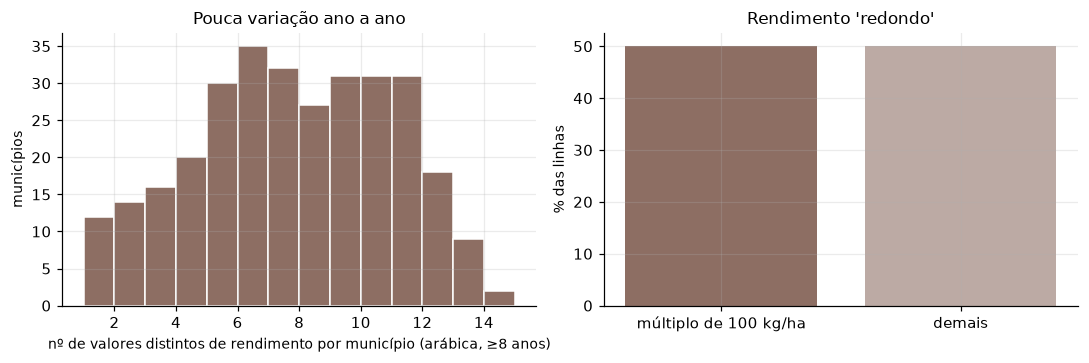

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(por_mun["valores_distintos"], bins=range(1, 16), color="#8d6e63", edgecolor="white")
ax[0].set(xlabel="nº de valores distintos de rendimento por município (arábica, ≥8 anos)", ylabel="municípios", title="Pouca variação ano a ano")
ar["arredondado_100"] = ar["rendimento_kg_ha"] % 100 == 0
ax[1].bar(["múltiplo de 100 kg/ha", "demais"], [ar.arredondado_100.mean() * 100, (1 - ar.arredondado_100.mean()) * 100], color=["#8d6e63", "#bcaaa4"])
ax[1].set(ylabel="% das linhas", title="Rendimento 'redondo'")
plt.tight_layout(); plt.savefig(FIG / "02_rendimento_repetido.png"); plt.show()

**Como ler:** à esquerda, o número de valores *distintos* de rendimento por município (quanto mais à esquerda, mais "congelado" o valor); à direita, a fração de valores "redondos" (múltiplos de 100 kg/ha). Os números impressos acima quantificam ambos (pares idênticos, municípios com valor único, valores mais repetidos). Tamanha repetição é compatível com **estimativas** (o IBGE coleta com agentes e órgãos locais). **Consequências para o projeto:** (a) a previsão municipal é limitada pelo "ruído de medição"; (b) correlações com clima ficam **atenuadas**; (c) baselines simples ("repita o ano anterior") são difíceis de bater — visto no notebook 06.

## 7. Reconciliação entre fontes: PAM (IBGE) × CONAB

As duas fontes medem coisas parecidas com metodologias diferentes (PAM: ano civil, municipal; CONAB: **safra**, estimativas por levantamento, UF). Convertemos a CONAB (mil sacas beneficiadas × 60 kg) para toneladas e comparamos SP/arábica.

Diferença relativa CONAB vs PAM (SP, arábica, 2012–2025): mediana 8.8% | máx 24.5%


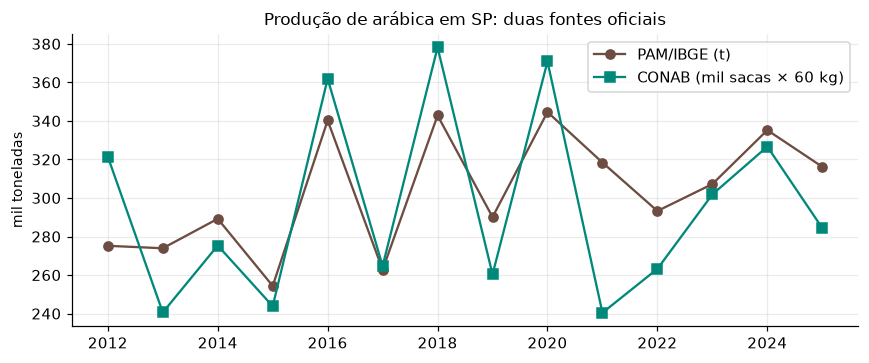

,ano,producao_conab_t,producao_pam_t,dif_%
0,2012,"321,396.00","275,183.00",16.79
1,2013,"240,606.00","273,913.00",-12.16
2,2014,"275,328.00","289,205.00",-4.80
3,2015,"243,834.00","254,348.00",-4.13
4,2016,"361,860.00","340,252.00",6.35
5,2017,"264,708.00","262,763.00",0.74
6,2018,"378,138.00","342,814.00",10.30
7,2019,"260,370.00","290,089.00",-10.24
8,2020,"370,842.00","344,610.00",7.61
9,2021,"240,432.00","318,395.00",-24.49


In [9]:
rec = q("select * from conab_vs_pam where uf = 'SP' and especie = 'arabica' and not estimativa order by ano")
rec["dif_%"] = 100 * rec["dif_rel"]
print(f"Diferença relativa CONAB vs PAM (SP, arábica, 2012–2025): mediana {rec['dif_%'].abs().median():.1f}% | máx {rec['dif_%'].abs().max():.1f}%")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(rec.ano, rec.producao_pam_t / 1e3, "-o", label="PAM/IBGE (t)", color="#6d4c41")
ax.plot(rec.ano, rec.producao_conab_t / 1e3, "-s", label="CONAB (mil sacas × 60 kg)", color="#00897b")
ax.set(ylabel="mil toneladas", title="Produção de arábica em SP: duas fontes oficiais"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "02_conab_vs_pam_sp.png"); plt.show()
rec[["ano", "producao_conab_t", "producao_pam_t", "dif_%"]]

**Interpretação:** as duas séries seguem o mesmo ritmo bienal, mas **os níveis divergem** (de poucos % a mais de 20% em certos anos). Não é erro de nenhuma das fontes: unidade e conceito diferem (safra × ano civil; estimativa × apuração municipal; café beneficiado × em grão). **Regra do projeto:** não misturar as duas na mesma série; usar a PAM para análise municipal e a CONAB como validação/contexto por UF.

## 8. Ingestão incremental e idempotente

- Cada requisição tem **chave determinística** (ex.: `uf35_arabica_2023`).
- Reexecutar: chave existente e fora da janela de revisão → **cached** (sem rede).
- Janela de revisão (últimos `PAM_REFRESH_RECENT_YEARS` anos): reconsultada; se o **hash do conteúdo não mudou** → **unchanged** (nada reescrito); se mudou → **updated** (troca atômica).
- Silver e gold são **reconstruídas de forma determinística** a partir da bronze: rodar duas vezes dá o mesmo resultado.

In [10]:
m = lake.manifest_df()
pam = m[(m.source == "ibge_pam") & (m.dataset == "pam_municipio")]
print(pam["n_fetches"].value_counts().rename("arquivos").rename_axis("nº de vezes consultado"))
print("\nAnos reconsultados (revisão do IBGE):", sorted({int(k.split('_')[2]) for k in pam[pam.n_fetches > 1].request_key}))
print("\nÚltimas execuções registradas:")
lake.runs_df().tail(8)[["run_id", "step", "status", "started_at", "ended_at"]]

nº de vezes consultado
1    74
4     6
Name: arquivos, dtype: int64

Anos reconsultados (revisão do IBGE): [2024, 2025]

Últimas execuções registradas:


,run_id,step,status,started_at,ended_at
0,f3f3ebc5,ingest,ok,2026-10-31 12:57:45.028053,2026-10-31 12:57:47.673891
1,f3f3ebc5,silver,ok,2026-10-31 12:57:47.676057,2026-10-31 12:57:50.195314
2,f3f3ebc5,gold,ok,2026-10-31 12:57:50.196131,2026-10-31 12:57:50.398255
3,f3f3ebc5,dq,failed,2026-10-31 12:57:50.398936,2026-10-31 12:57:50.636117
4,d0ab206a,ingest,ok,2026-10-31 12:58:21.228028,2026-10-31 12:58:23.787997
5,d0ab206a,silver,ok,2026-10-31 12:58:23.789116,2026-10-31 12:58:26.298156
6,d0ab206a,gold,ok,2026-10-31 12:58:26.298772,2026-10-31 12:58:26.486481
7,d0ab206a,dq,ok,2026-10-31 12:58:26.487159,2026-10-31 12:58:26.737324


In [11]:
# Idempotência da silver: reconstruir duas vezes dá EXATAMENTE o mesmo resultado
a, _ = silver.build_pam_municipio(lake, write=False)
b, _ = silver.build_pam_municipio(lake, write=False)
key = ["cod_ibge", "especie", "ano"]
same = a.sort_values(key).reset_index(drop=True).equals(b.sort_values(key).reset_index(drop=True))
print("Silver idêntica nas duas reconstruções:", same, "| linhas:", len(a))

Silver idêntica nas duas reconstruções: True | linhas: 51040


## 9. Particionamento Parquet
- `pam_municipio`: partições `especie=…/ano=…` (filtros típicos: uma espécie, um intervalo de anos).
- `clima_diario`: partição `ano=…` (janelas fenológicas leem poucos anos).
- Tabelas pequenas (dimensões, preços): **sem partição** — particionar tabelas pequenas só cria muitos arquivos minúsculos (*small files problem*); medido no notebook 07.

In [12]:
import pathlib
for t in ["pam_municipio", "clima_diario", "dim_municipio"]:
    base = lake.silver / t
    files = list(base.rglob("*.parquet"))
    print(f"{t:<15} arquivos: {len(files):>4} | tamanho total: {sum(f.stat().st_size for f in files)/1e6:6.2f} MB | exemplo: {files[0].relative_to(base)}")

pam_municipio   arquivos:   80 | tamanho total:   1.22 MB | exemplo: especie=arabica/ano=2016/data_0.parquet
clima_diario    arquivos:   26 | tamanho total:   5.50 MB | exemplo: ano=2016/data_0.parquet
dim_municipio   arquivos:    1 | tamanho total:   0.03 MB | exemplo: part-0.parquet


## 10. Exercícios
1. Quantos municípios paulistas **nunca** aparecem com `quantidade_t > 0` em arábica? Eles entram no painel de modelagem?
2. Escreva uma nova checagem de qualidade (ex.: `area_colhida_ha ≤ area_destinada_ha`) em `quality.py` e rode-a. Qual severidade escolheria? Por quê?
3. Se o IBGE revisasse o PAM de 2023, o que o pipeline faria? Faça um experimento alterando `PAM_REFRESH_RECENT_YEARS` e acompanhe o manifesto.